# GuardedTrainer — Zentrale Visualisierungen

1. **Einzel-Beispiel (Gesamtskala + Zoom):** `logistic-mid` Annealing $\rightarrow$ Lucas-Vollkollaps $\rightarrow$ Rollback ($t-1$) $\rightarrow$ **ControlVAE-PI Hold** (100 Epochen).
2. **Erfolgs-Statistik & Fehleranalyse:** Wie oft wurde gehalten? Aufschlüsselung nach Datensatz, allen 16 Configs sowie LR- & Dropout-Sweep.
3. **Bonus:** Rate-Distortion-Kurve (`Kneedle` Sweet Spot vs. `PI-Hold` vs. `Vollkollaps` auf `ontix_standard`).

In [1]:
from pathlib import Path
import json
import sys
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/core_real_final").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

PILOT_DIR = ROOT / "results/eps01_activation_pilot/beta_guard_vae"
NOAH_ZIP = ROOT / "results/results_noah.zip"
LOWEST8_DIR = ROOT / "results/lowest8_lowvar_grid_ki030_eps001/beta_guard_vae"

plt.rcParams.update({
    "figure.dpi": 135,
    "savefig.dpi": 300,
    "font.size": 10.5,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "legend.frameon": True,
    "legend.framealpha": 0.92,
})

C_BLUE = "#2563EB"    # Annealing
C_GREEN = "#059669"   # ControlVAE-PI
C_RED = "#DC2626"     # Vollkollaps
C_AMBER = "#D97706"   # Rollback / Setpoint / Fallback
C_PURPLE = "#7C3AED"  # KL-Kurve
C_GRAY = "#475569"

def load_run(run_dir: Path):
    rows = [json.loads(l) for l in (run_dir / "collapse_history.jsonl").read_text().splitlines() if l.strip()]
    return pd.DataFrame(rows), json.loads((run_dir / "guard_summary.json").read_text())

/home/nickok/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-kkuayn5r because there was an issue with the default path (/home/nickok/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## 1. Beispiel-Verlauf in EINEM Plot: Annealing $\rightarrow$ Rollback $\rightarrow$ ControlVAE-PI

* **Linke y-Achse:** Effektives $\beta(t)$ — **Blau** = offenes `logistic-mid`-Annealing, **Rot ($\times$)** = Lucas-Vollkollaps, **Orange (gestrichelt)** = Rollback auf $t-1$, **Grün** = 100 Epochen ControlVAE-PI.
* **Rechte y-Achse:** Trainings-KL $R_{\text{train}}(t)$ (Violett) gegen den eingefrorenen Setpoint $C$ mit $\pm 20\%$-Zielband.

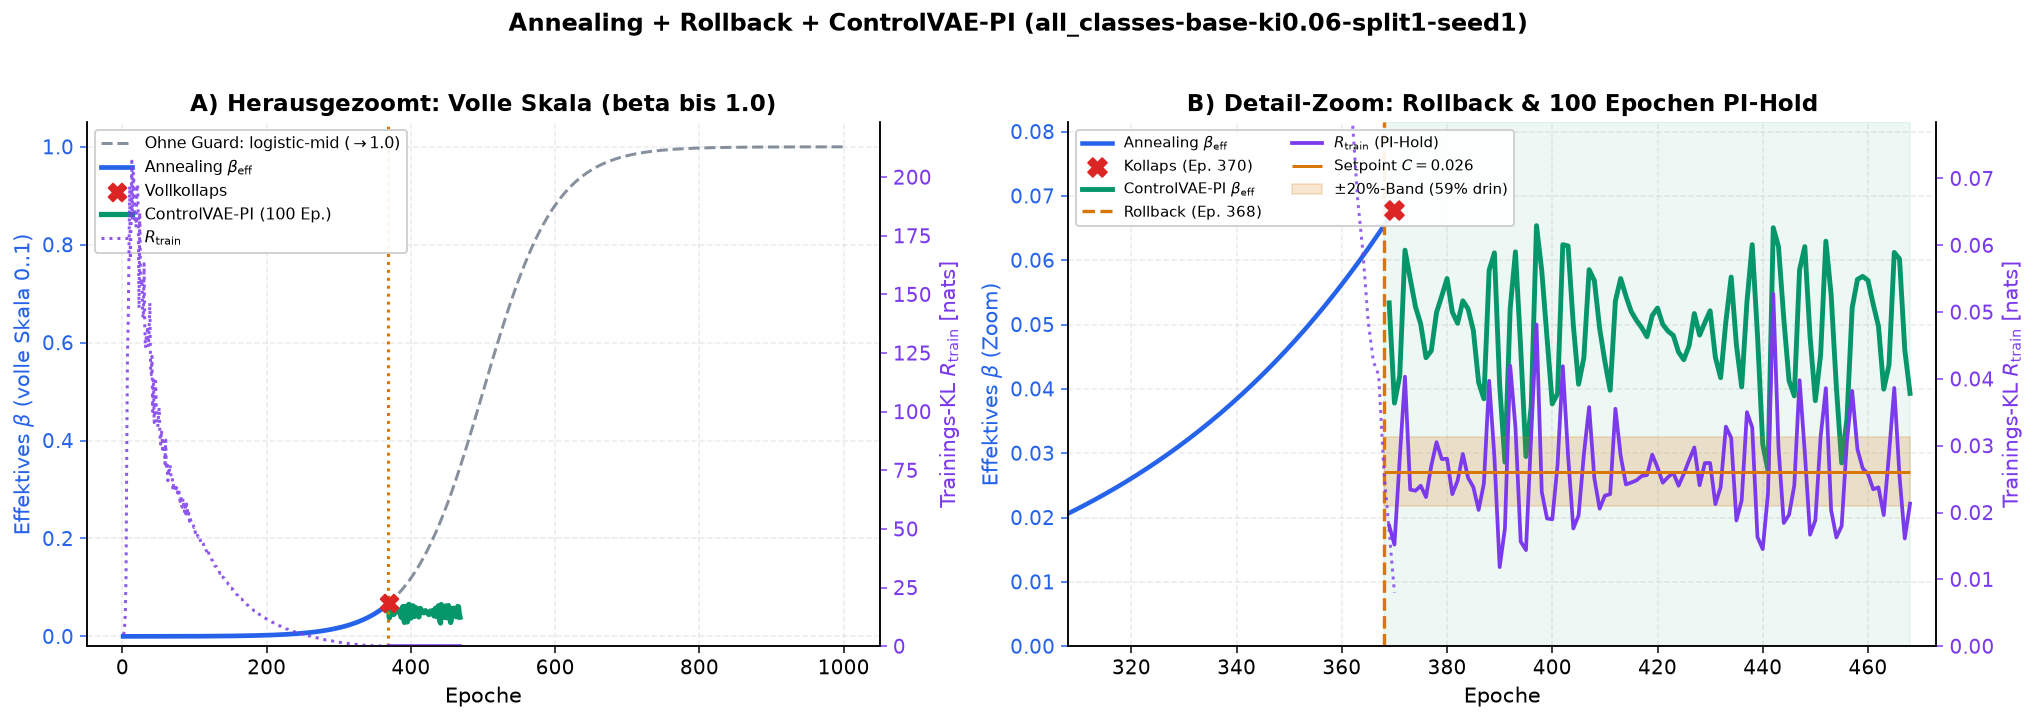

Zusammenfassung: Kollaps Ep. 370 -> Handover Ep. 368 | beta_ho = 0.0654 -> beta_PI = 0.0485 | Restarts = 1 | 59.0% im +/-20%-Band | Achsen gestorben = 0


In [2]:
RUN_NAME = "all_classes-base-ki0.06-split1-seed1"
df_run, sum_run = load_run(PILOT_DIR / RUN_NAME)

final_att = int(df_run["attempt"].max())
anneal = df_run[df_run["phase"] == "annealing"].copy()
collapse = df_run[df_run["lookback_handover"] == True].iloc[0]
control = df_run[(df_run["phase"].isin(["control", "done"])) & (df_run["attempt"] == final_att)].copy()

ho_ep = int(sum_run["trigger_epoch"]) + 1
C_val = float(sum_run["target_kl"])
lh = sum_run["lucas_handover"]
band_pct = 100.0 * float(lh["kl_in_target_band_share"])

# Theoretischer offener logistic-mid Schedule bis Ep. 1000 (wohin es OHNE Guard gehen wuerde)
ep_all = np.arange(1, 1001)
sched_full = 1.0 / (1.0 + np.exp(-0.02 * (ep_all - 500)))

fig, (ax_out, ax_in) = plt.subplots(1, 2, figsize=(15.2, 5.2), gridspec_kw={"width_ratios": [1.05, 1.15]})

# === LINKS: HERAUSGEZOOMT (volle Skala beta 0..1.0 & volle KL) ===
ax_out.plot(ep_all, sched_full, color=C_GRAY, ls="--", lw=1.6, alpha=0.65, label=r"Ohne Guard: logistic-mid ($\to 1.0$)")
ax_out.plot(anneal["epoch_number"], anneal["effective_beta"], color=C_BLUE, lw=2.5, label=r"Annealing $\beta_{\mathrm{eff}}$")
ax_out.scatter([collapse["epoch_number"]], [collapse["effective_beta"]], color=C_RED, s=90, marker="X", zorder=6, label="Vollkollaps")
ax_out.plot(control["epoch_number"], control["effective_beta"], color=C_GREEN, lw=2.8, label="ControlVAE-PI (100 Ep.)")
ax_out.axvline(ho_ep, color=C_AMBER, ls=":", lw=1.6)
ax_out.set_xlabel("Epoche")
ax_out.set_ylabel(r"Effektives $\beta$ (volle Skala 0..1)", color=C_BLUE)
ax_out.tick_params(axis="y", colors=C_BLUE)
ax_out.set_ylim(-0.02, 1.05)

ax_out2 = ax_out.twinx()
ax_out2.spines["top"].set_visible(False)
ax_out2.grid(False)
ax_out2.plot(anneal["epoch_number"], anneal["R_train_nats"], color=C_PURPLE, lw=1.6, ls=":", alpha=0.85, label=r"$R_{\mathrm{train}}$")
ax_out2.plot(control["epoch_number"], control["R_train_nats"], color=C_PURPLE, lw=2.0)
ax_out2.set_ylabel(r"Trainings-KL $R_{\mathrm{train}}$ [nats]", color=C_PURPLE)
ax_out2.tick_params(axis="y", colors=C_PURPLE)
ax_out2.set_ylim(0, anneal["R_train_nats"].max() * 1.08)

h1, l1 = ax_out.get_legend_handles_labels()
h2, l2 = ax_out2.get_legend_handles_labels()
ax_out.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8.3)
ax_out.set_title("A) Herausgezoomt: Volle Skala (beta bis 1.0)")

# === RECHTS: DETAIL-ZOOM auf Rollback & 100-Epochen PI-Hold ===
ax_in.axvspan(ho_ep, control["epoch_number"].max(), color=C_GREEN, alpha=0.07)
ax_in.plot(anneal["epoch_number"], anneal["effective_beta"], color=C_BLUE, lw=2.4, label=r"Annealing $\beta_{\mathrm{eff}}$")
ax_in.scatter([collapse["epoch_number"]], [collapse["effective_beta"]], color=C_RED, s=100, marker="X", zorder=6,
              label=f"Kollaps (Ep. {int(collapse['epoch_number'])})")
ax_in.plot(control["epoch_number"], control["effective_beta"], color=C_GREEN, lw=2.6, label=r"ControlVAE-PI $\beta_{\mathrm{eff}}$")
ax_in.axvline(ho_ep, color=C_AMBER, ls="--", lw=1.8, label=f"Rollback (Ep. {ho_ep})")
ax_in.set_xlim(ho_ep - 60, control["epoch_number"].max() + 5)
ax_in.set_ylim(0, max(anneal["effective_beta"].max(), control["effective_beta"].max()) * 1.2)
ax_in.set_xlabel("Epoche")
ax_in.set_ylabel(r"Effektives $\beta$ (Zoom)", color=C_BLUE)
ax_in.tick_params(axis="y", colors=C_BLUE)

ax_in2 = ax_in.twinx()
ax_in2.spines["top"].set_visible(False)
ax_in2.grid(False)
ax_in2.plot(anneal["epoch_number"], anneal["R_train_nats"], color=C_PURPLE, lw=1.6, ls=":", alpha=0.8)
ax_in2.plot(control["epoch_number"], control["R_train_nats"], color=C_PURPLE, lw=2.0, label=r"$R_{\mathrm{train}}$ (PI-Hold)")
ax_in2.hlines(C_val, ho_ep, control["epoch_number"].max(), color=C_AMBER, lw=1.6, label=f"Setpoint $C = {C_val:.3f}$")
ax_in2.fill_between([ho_ep, control["epoch_number"].max()], 0.8 * C_val, 1.2 * C_val,
                    color=C_AMBER, alpha=0.18, label=rf"$\pm 20\%$-Band ({band_pct:.0f}% drin)")
ax_in2.set_ylabel(r"Trainings-KL $R_{\mathrm{train}}$ [nats]", color=C_PURPLE)
ax_in2.tick_params(axis="y", colors=C_PURPLE)
ax_in2.set_ylim(0, C_val * 3.0)

h1, l1 = ax_in.get_legend_handles_labels()
h2, l2 = ax_in2.get_legend_handles_labels()
ax_in.legend(h1 + h2, l1 + l2, loc="upper left", ncol=2, fontsize=8.0)
ax_in.set_title("B) Detail-Zoom: Rollback & 100 Epochen PI-Hold")

fig.suptitle(f"Annealing + Rollback + ControlVAE-PI ({RUN_NAME})", y=1.02, fontweight="bold")
fig.tight_layout()
plt.show()

ep_col = int(collapse["epoch_number"])
print(
    f"Zusammenfassung: Kollaps Ep. {ep_col} -> Handover Ep. {ho_ep} | "
    f"beta_ho = {lh['beta_handover_effective']:.4f} -> beta_PI = {lh['beta_final_mean']:.4f} | "
    f"Restarts = {lh['restarts']} | {band_pct:.1f}% im +/-20%-Band | Achsen gestorben = {lh['axes_died_during_hold']}"
)


## 2. Statistik: Wie oft wurde erfolgreich gehalten?

Vergleicht das abgeschlossene **432-Run-Grid** (`results_noah.zip`, $\epsilon = 0.01, K_i = 0.06$, 100 Epochen Hold) direkt mit dem laufenden **`lowest8_lowvar`-Grid** (`ki = 0.30`).

,Gruppe,Runs,Gehalten (100 Ep.),Kein Kollaps,max_restarts,Haltequote bei Kollaps,Test-Kollaps (gehaltene)
0,all_classes (ki=0.06),144,109 (75.7%),21 (14.6%),14 (9.7%),88.6%,0/109
1,ontix_standard (ki=0.06),144,102 (70.8%),33 (22.9%),9 (6.2%),91.9%,0/102
2,weak_signal_lowvar (ki=0.06),144,12 (8.3%),36 (25.0%),96 (66.7%),11.1%,1/12
3,lowest8_lowvar (ki=0.30),144,75 (52.1%),36 (25.0%),33 (22.9%),69.4%,5/75


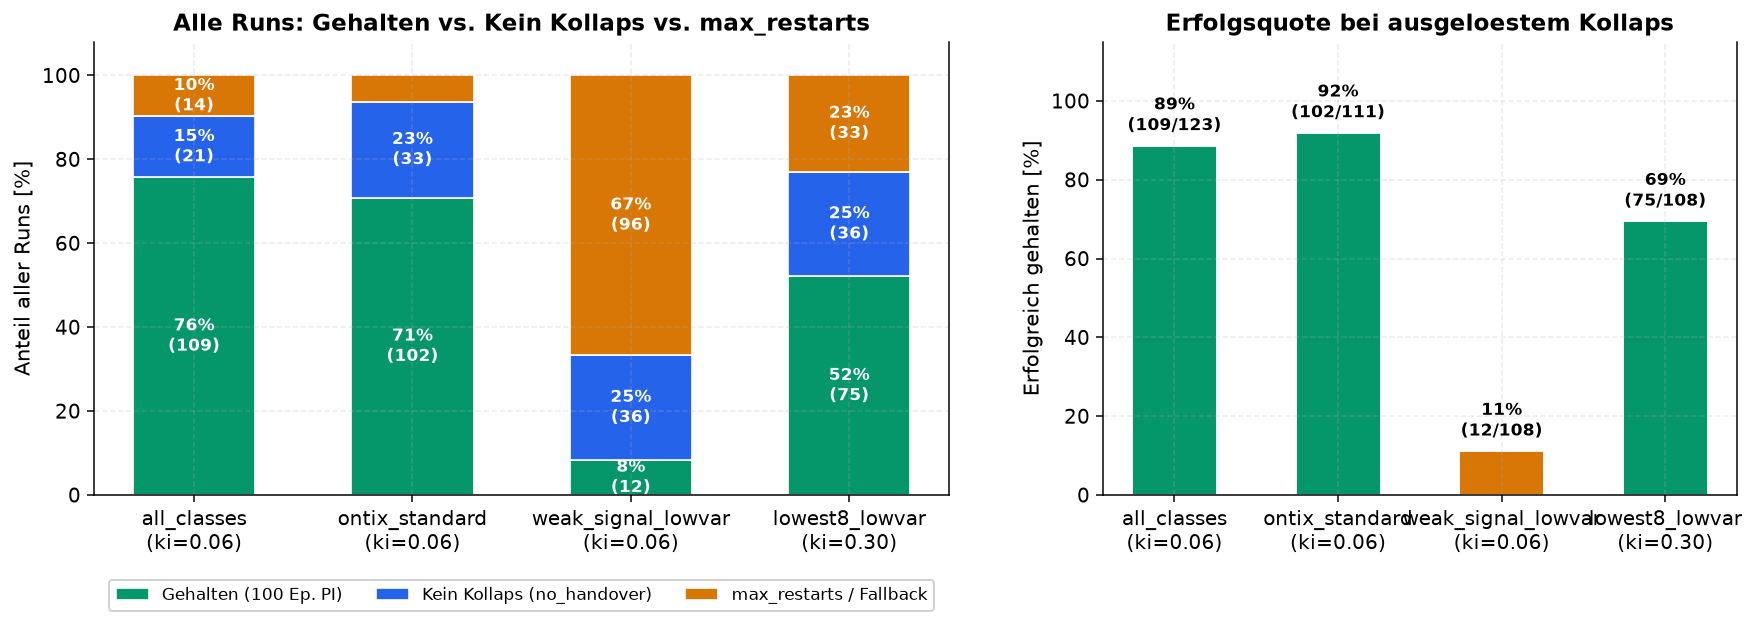

In [3]:
def summarize_outcome(s: dict) -> str:
    lh = s.get("lucas_handover") or {}
    phase, reason = lh.get("phase"), lh.get("fail_reason")
    if phase == "done" and reason is None:
        return "Gehalten (100 Ep. PI)"
    if phase == "annealing":
        return "Kein Kollaps (no_handover)"
    if reason in ("max_restarts", "max_restarts_fallback"):
        return "max_restarts / Fallback"
    return "Sonstiges"

records = []
# 1) 432 Runs aus results_noah.zip
with zipfile.ZipFile(NOAH_ZIP) as zf:
    for name in zf.namelist():
        if not name.endswith("guard_summary.json"):
            continue
        s = json.loads(zf.read(name))
        lh = s.get("lucas_handover") or {}
        ft = lh.get("final_lucas_test") or {}
        g = next(k for k in ("all_classes", "ontix_standard", "weak_signal_lowvar") if k in name)
        label = f"{g}\n(ki=0.06)"
        records.append({
            "Gruppe": label,
            "Status": summarize_outcome(s),
            "test_collapse": ft.get("lucas_full_collapse_train_eval"),
            "beta_final": lh.get("beta_final_mean"),
        })

# 2) Neues lowest8_lowvar Grid (ki=0.30) — liest automatisch alle fertigen Runs
if LOWEST8_DIR.exists():
    for sp in sorted(LOWEST8_DIR.glob("*/guard_summary.json")):
        s = json.loads(sp.read_text())
        lh = s.get("lucas_handover") or {}
        ft = lh.get("final_lucas_test") or {}
        records.append({
            "Gruppe": "lowest8_lowvar\n(ki=0.30)",
            "Status": summarize_outcome(s),
            "test_collapse": ft.get("lucas_full_collapse_train_eval"),
            "beta_final": lh.get("beta_final_mean"),
        })

df_stat = pd.DataFrame(records)
order_groups = [
    "all_classes\n(ki=0.06)",
    "ontix_standard\n(ki=0.06)",
    "weak_signal_lowvar\n(ki=0.06)",
    "lowest8_lowvar\n(ki=0.30)",
]
order_groups = [g for g in order_groups if g in df_stat["Gruppe"].unique()]
order_status = [
    ("Gehalten (100 Ep. PI)", C_GREEN),
    ("Kein Kollaps (no_handover)", C_BLUE),
    ("max_restarts / Fallback", C_AMBER),
]

# Saubere Uebersichtstabelle
summary_rows = []
for g in order_groups:
    sub = df_stat[df_stat["Gruppe"] == g]
    n = len(sub)
    held = int((sub["Status"] == "Gehalten (100 Ep. PI)").sum())
    noho = int((sub["Status"] == "Kein Kollaps (no_handover)").sum())
    maxr = int((sub["Status"] == "max_restarts / Fallback").sum())
    triggered = held + maxr
    held_sub = sub[sub["Status"] == "Gehalten (100 Ep. PI)"]
    test_fc = int(held_sub["test_collapse"].fillna(False).sum())
    summary_rows.append({
        "Gruppe": g.replace("\n", " "),
        "Runs": n,
        "Gehalten (100 Ep.)": f"{held} ({100*held/n:.1f}%)",
        "Kein Kollaps": f"{noho} ({100*noho/n:.1f}%)",
        "max_restarts": f"{maxr} ({100*maxr/n:.1f}%)",
        "Haltequote bei Kollaps": f"{100*held/triggered:.1f}%" if triggered else "—",
        "Test-Kollaps (gehaltene)": f"{test_fc}/{held}",
    })
display(pd.DataFrame(summary_rows))

# --- Doppel-Plot: Links 100%-Stacked-Bar, Rechts Haltequote unter allen Kollaps-Runs ---
ct = pd.crosstab(df_stat["Gruppe"], df_stat["Status"]).reindex(order_groups).fillna(0)
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100.0

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.8), gridspec_kw={"width_ratios": [1.35, 1.0]})

# Links: 100% Stacked Bar
ax = axes[0]
x = np.arange(len(order_groups))
bottom = np.zeros(len(order_groups))
for col, color in order_status:
    vals = ct_pct[col].values if col in ct_pct.columns else np.zeros(len(order_groups))
    cnts = ct[col].values if col in ct.columns else np.zeros(len(order_groups))
    ax.bar(x, vals, bottom=bottom, width=0.56, color=color, edgecolor="white", lw=0.9, label=col)
    for xi, v, n_c, b in zip(x, vals, cnts, bottom):
        if v >= 7.5:
            ax.text(xi, b + v / 2, f"{v:.0f}%\n({int(n_c)})", ha="center", va="center",
                    color="white", fontweight="bold", fontsize=8.8)
    bottom += vals
ax.set_xticks(x)
ax.set_xticklabels(order_groups)
ax.set_ylim(0, 108)
ax.set_ylabel("Anteil aller Runs [%]")
ax.set_title("Alle Runs: Gehalten vs. Kein Kollaps vs. max_restarts")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=8.8)

# Rechts: Haltequote NUR auf Runs, die tatsaechlich kollabiert sind (held / (held + max_restarts))
ax = axes[1]
hold_rates = []
labels_r = []
for g in order_groups:
    h = ct.loc[g].get("Gehalten (100 Ep. PI)", 0)
    m = ct.loc[g].get("max_restarts / Fallback", 0)
    rate = 100.0 * h / (h + m) if (h + m) > 0 else 0.0
    hold_rates.append(rate)
    labels_r.append(f"{int(h)}/{int(h+m)}")
bar_colors = [C_GREEN if r >= 60 else C_AMBER for r in hold_rates]
bars = ax.bar(x, hold_rates, width=0.52, color=bar_colors, edgecolor="white")
for xi, r, txt in zip(x, hold_rates, labels_r):
    ax.text(xi, r + 2.5, f"{r:.0f}%\n({txt})", ha="center", va="bottom", fontweight="bold", fontsize=9.2)
ax.set_xticks(x)
ax.set_xticklabels(order_groups)
ax.set_ylim(0, 115)
ax.set_ylabel("Erfolgreich gehalten [%]")
ax.set_title("Erfolgsquote bei ausgeloestem Kollaps")

fig.tight_layout()
plt.show()

### 2B. Aufschlüsselung nach Hyperparameter-Konfiguration (alle 16 Varianten)

Links: **`all_classes` + `ontix_standard`** (`ki=0.06`, je 18 Runs/Variante — **180 / 180 = 100 %** auf allen 10 normalen Configs!).  
Rechts: neues **`lowest8_lowvar`** (`ki=0.30`, je 9 Runs/Variante — ohne das alte 2-Klassen-`weak_signal`).

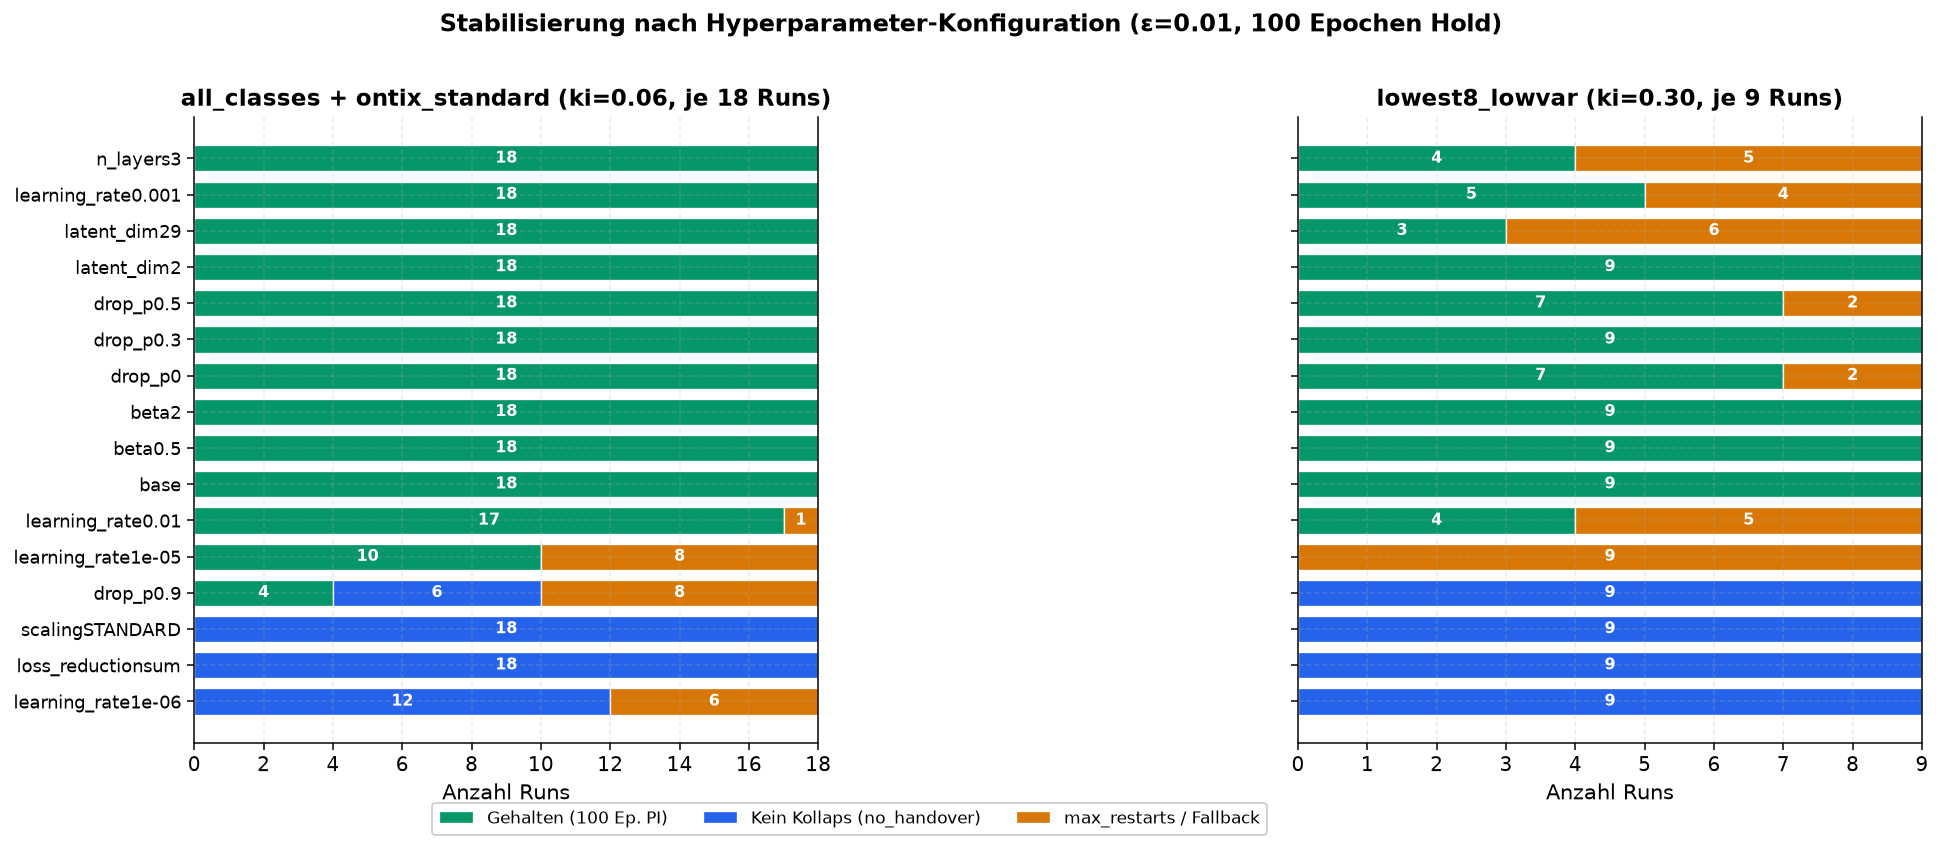

In [4]:
var_rows = []
with zipfile.ZipFile(NOAH_ZIP) as zf:
    for name in zf.namelist():
        if not name.endswith("guard_summary.json"):
            continue
        s = json.loads(zf.read(name))
        run_dir = name.split("/")[-2]
        parts = run_dir.split("-controlvae-")[0].split("-", 2)
        group, variant = parts[1], parts[2]
        var_rows.append({"group": group, "variant": variant, "Status": summarize_outcome(s)})

df_var = pd.DataFrame(var_rows)
df_main = df_var[df_var["group"] != "weak_signal_lowvar"]

# Neues lowest8_lowvar Grid (144 Runs, ki=0.30)
l8_rows = []
if LOWEST8_DIR.exists():
    for sp in sorted(LOWEST8_DIR.glob("*/guard_summary.json")):
        s = json.loads(sp.read_text())
        run_dir = sp.parent.name  # tcga-lowest8_lowvar-<variant>-ki0.30-splitX-seedY
        variant = run_dir.split("-ki0.30-")[0].split("lowest8_lowvar-", 1)[1]
        l8_rows.append({"group": "lowest8_lowvar", "variant": variant, "Status": summarize_outcome(s)})
df_l8 = pd.DataFrame(l8_rows)

ct_main = pd.crosstab(df_main["variant"], df_main["Status"]).fillna(0)
sort_order = (
    ct_main.assign(
        _h=ct_main.get("Gehalten (100 Ep. PI)", 0),
        _n=ct_main.get("Kein Kollaps (no_handover)", 0),
    )
    .sort_values(["_h", "_n"], ascending=[True, True])
    .index.tolist()
)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.2), sharey=True)
for ax, (title, sub_df) in zip(axes, [
    ("all_classes + ontix_standard (ki=0.06, je 18 Runs)", df_main),
    ("lowest8_lowvar (ki=0.30, je 9 Runs)", df_l8),
]):
    ct_v = pd.crosstab(sub_df["variant"], sub_df["Status"]).reindex(sort_order).fillna(0)
    y = np.arange(len(sort_order))
    left = np.zeros(len(sort_order))
    for col, color in order_status:
        vals = ct_v[col].values if col in ct_v.columns else np.zeros(len(sort_order))
        ax.barh(y, vals, left=left, height=0.72, color=color, edgecolor="white", lw=0.7, label=col)
        for yi, v, lft in zip(y, vals, left):
            if v >= 1:
                ax.text(lft + v / 2, yi, f"{int(v)}", ha="center", va="center", color="white", fontweight="bold", fontsize=8.5)
        left += vals
    ax.set_yticks(y)
    ax.set_yticklabels(sort_order, fontsize=9.5)
    ax.set_xlabel("Anzahl Runs")
    ax.set_title(title)

axes[0].legend(loc="lower center", bbox_to_anchor=(1.05, -0.16), ncol=3, fontsize=9.2)
fig.suptitle("Stabilisierung nach Hyperparameter-Konfiguration (ε=0.01, 100 Epochen Hold)", y=1.01, fontweight="bold")
fig.tight_layout()
plt.show()


### 2C. Vollständige Fehleranalyse: Woher kommen alle 119 `max_restarts`?

**100 % aller 119 `max_restarts` sind mechanistisch erklärt:** 96× `weak_signal_lowvar` (`B=2`), 14× zu kleine Lernrate (`1e-5`/`1e-6`), 8× extremer Dropout (`0.9`), 1× `lr=0.01` — und **0×** auf allen 10 normalen Configs.

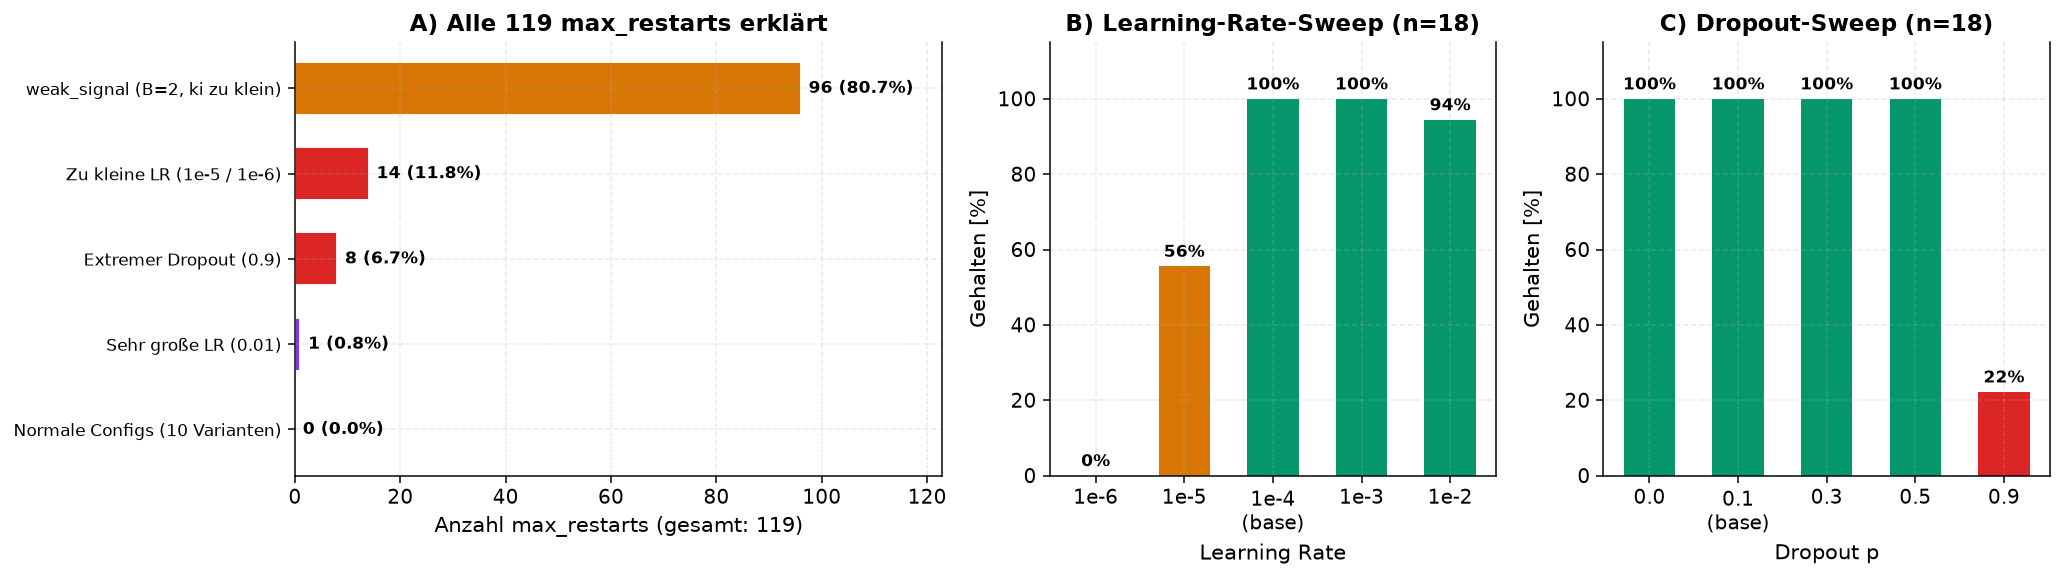

In [5]:
fail_df = df_var[df_var["Status"] == "max_restarts / Fallback"].copy()
def categorize_fail(row):
    if row["group"] == "weak_signal_lowvar":
        return "weak_signal (B=2, ki zu klein)"
    if row["variant"] in ("learning_rate1e-05", "learning_rate1e-06"):
        return "Zu kleine LR (1e-5 / 1e-6)"
    if row["variant"] == "drop_p0.9":
        return "Extremer Dropout (0.9)"
    if row["variant"] == "learning_rate0.01":
        return "Sehr große LR (0.01)"
    return "Normale Configs"

fail_df["Ursache"] = fail_df.apply(categorize_fail, axis=1)
cause_order = [
    "weak_signal (B=2, ki zu klein)",
    "Zu kleine LR (1e-5 / 1e-6)",
    "Extremer Dropout (0.9)",
    "Sehr große LR (0.01)",
    "Normale Configs (10 Varianten)",
]
cause_counts = [int((fail_df["Ursache"] == c).sum()) if c != "Normale Configs (10 Varianten)" else 0 for c in cause_order]
total_fails = len(fail_df)

# Learning-Rate-Sweep & Dropout-Sweep (all_classes + ontix_standard, je 18 Runs)
lr_map = [
    ("1e-6", "learning_rate1e-06"),
    ("1e-5", "learning_rate1e-05"),
    ("1e-4\n(base)", "base"),
    ("1e-3", "learning_rate0.001"),
    ("1e-2", "learning_rate0.01"),
]
drop_map = [
    ("0.0", "drop_p0"),
    ("0.1\n(base)", "base"),
    ("0.3", "drop_p0.3"),
    ("0.5", "drop_p0.5"),
    ("0.9", "drop_p0.9"),
]

def done_pct(variant_name):
    sub = df_main[df_main["variant"] == variant_name]
    return 100.0 * (sub["Status"] == "Gehalten (100 Ep. PI)").mean()

fig, axes = plt.subplots(1, 3, figsize=(15.4, 4.4), gridspec_kw={"width_ratios": [1.45, 1.0, 1.0]})

# Panel A: Ursachen aller 119 max_restarts
ax = axes[0]
y = np.arange(len(cause_order))[::-1]
bar_c = [C_AMBER, C_RED, C_RED, C_PURPLE, C_GREEN]
ax.barh(y, cause_counts, color=bar_c, height=0.62, edgecolor="white")
for yi, cnt in zip(y, cause_counts):
    ax.text(cnt + 1.5, yi, f"{cnt} ({100*cnt/total_fails:.1f}%)", va="center", fontweight="bold", fontsize=9.2)
ax.set_yticks(y)
ax.set_yticklabels(cause_order, fontsize=9.3)
ax.set_xlim(0, max(cause_counts) * 1.28)
ax.set_xlabel("Anzahl max_restarts (gesamt: 119)")
ax.set_title("A) Alle 119 max_restarts erklärt")

# Panel B: Learning-Rate-Sweep
ax = axes[1]
lr_lbls = [k for k, _ in lr_map]
lr_vals = [done_pct(v) for _, v in lr_map]
ax.bar(range(len(lr_lbls)), lr_vals, width=0.58, color=[C_GREEN if v >= 90 else (C_AMBER if v >= 40 else C_RED) for v in lr_vals])
for i, v in enumerate(lr_vals):
    ax.text(i, v + 2.5, f"{v:.0f}%", ha="center", fontweight="bold", fontsize=9.2)
ax.set_xticks(range(len(lr_lbls)))
ax.set_xticklabels(lr_lbls)
ax.set_ylim(0, 115)
ax.set_ylabel("Gehalten [%]")
ax.set_xlabel("Learning Rate")
ax.set_title("B) Learning-Rate-Sweep (n=18)")

# Panel C: Dropout-Sweep
ax = axes[2]
dr_lbls = [k for k, _ in drop_map]
dr_vals = [done_pct(v) for _, v in drop_map]
ax.bar(range(len(dr_lbls)), dr_vals, width=0.58, color=[C_GREEN if v >= 90 else C_RED for v in dr_vals])
for i, v in enumerate(dr_vals):
    ax.text(i, v + 2.5, f"{v:.0f}%", ha="center", fontweight="bold", fontsize=9.2)
ax.set_xticks(range(len(dr_lbls)))
ax.set_xticklabels(dr_lbls)
ax.set_ylim(0, 115)
ax.set_ylabel("Gehalten [%]")
ax.set_xlabel("Dropout p")
ax.set_title("C) Dropout-Sweep (n=18)")

fig.tight_layout()
plt.show()
